# Dar_043: monthly and quarterly environmental context

Historical UTC year-months and calendar quarters, **not lunar seasons**. Reuses checked CRaTER/GOES daily summaries, the full downloaded SOLSTICE FUV/MUV record and 36 ARTEMIS THB monthly files. Quality/coverage and spacecraft position stay explicit. No local dose, charging voltage, forecast or candidate safety label is inferred.

In [1]:
from pathlib import Path
import sys, json
root = Path.cwd().resolve()
while not (root / "outline.md").is_file():
    if root == root.parent: raise RuntimeError("Run inside the repository")
    root = root.parent
sys.path[:0] = [str(root / "darrel stuff/EDA/shared"), str(root / "darrel stuff/EDA/Moon/Stage3_Requirements"), str(root / "darrel stuff"), str(root)]
from stage3_temporal_eda import execute
folder, findings = execute()
print(folder)

UV parsed: MUV 5789 daily spectra


UV parsed: FUV 5791 daily spectra


Plasma parsed: thb_l2_merged_20231001_v01.cdf 10060


Plasma parsed: thb_l2_merged_20231101_v01.cdf 10058


Plasma parsed: thb_l2_merged_20231201_v01.cdf 10828


Plasma parsed: thb_l2_merged_20240101_v01.cdf 10195


... (30 outputs left out)

Plasma parsed: thb_l2_merged_20260801_v01.cdf 4720


Plasma parsed: thb_l2_merged_20260901_v01.cdf 7621


{
  "sample": false,
  "series": 101,
  "daily_rows": 65357,
  "monthly_rows": 2352,
  "quarterly_rows": 856,
  "plasma_files": 36,
  "uv_valid_days": [
    {
      "channel": "FUV",
      "valid_dates": 5700
    },
    {
      "channel": "MUV",
      "valid_dates": 5760
    }
  ],
  "calendar_bins_are_lunar_seasons": false,
  "simultaneous_UV_plasma_analysis": false,
  "candidate_operational_conclusion": "Unknown",
  "new_safety_limits": false,
  "holds": [
    "Calendar contrasts are descriptive, not recurring seasonality or future forecasts",
    "UV does not overlap recent radiation/plasma; no simultaneous correlation",
    "GOES platforms/channels/versions stay separate; SEC counters are not dose",
    "Plasma strata describe spacecraft geometry, not certified plasma regimes or surface charging",
    "Plasma record-weighted statistics have mixed cadence; elapsed valid coverage remains unknown",
    "Full calendar denominators include partial edge periods; missing/flagged data is n

C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\stage3_temporal_environment\20261109T183729619637Z_3d72dc


## Coverage and monthly / quarterly levels

Each series keeps its instrument, channel, version, UV mode and plasma position stratum. Period medians and percentiles describe **daily statistics**, not pooled raw records. Full calendar denominators retain partial edge periods and missing observations. Plasma cadence is mixed, so record support is not elapsed valid time. UV daily means do not resolve short flare peaks.

In [2]:
import pandas as pd
from IPython.display import display
support = pd.read_csv(folder / "temporal_support.csv")
monthly = pd.read_csv(folder / "monthly_context.csv")
quarterly = pd.read_csv(folder / "quarterly_context.csv")
display(support[["series_id", "start_utc", "stop_exclusive_utc", "recorded_dates", "valid_dates", "spatial_scope"]])
display(monthly.head(12))
display(quarterly.head(12))
display(pd.read_csv(folder / "cross_dataset_overlap.csv"))

,series_id,start_utc,stop_exclusive_utc,recorded_dates,valid_dates,spatial_scope
0,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2023-10-01T00:00:00+00:00,2026-09-30T00:00:00+00:00,1020,1014,"spacecraft position, NOT candidate surface pot..."
1,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_5...,2023-11-19T00:00:00+00:00,2026-09-30T00:00:00+00:00,760,758,"spacecraft position, NOT candidate surface pot..."
2,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_nonnegativ...,2023-10-01T00:00:00+00:00,2026-09-30T00:00:00+00:00,1017,1014,"spacecraft position, NOT candidate surface pot..."
3,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_nonnegativ...,2023-10-01T00:00:00+00:00,2026-09-30T00:00:00+00:00,787,786,"spacecraft position, NOT candidate surface pot..."
4,PLASMA_THB_v01_thb_fgs_btotal_all_positions,2023-10-01T00:00:00+00:00,2026-09-30T00:00:00+00:00,1040,1038,"spacecraft position, NOT candidate surface pot..."
...,...,...,...,...,...,...
96,RAD_GOES19_3-0-3_s1_c7_41000.0-74000.0keV,2026-01-10T00:00:00+00:00,2026-11-01T00:00:00+00:00,295,193,"GOES, NOT local lunar flux or transported dose"
97,RAD_GOES19_3-0-3_s1_c8_78000.0-99700.0keV,2026-01-10T00:00:00+00:00,2026-11-01T00:00:00+00:00,295,192,"GOES, NOT local lunar flux or transported dose"
98,RAD_GOES19_3-0-3_s1_c9_97900.0-120300.0keV,2026-01-10T00:00:00+00:00,2026-11-01T00:00:00+00:00,295,1,"GOES, NOT local lunar flux or transported dose"
99,UV_SOLSTICE_FUV_mode11_v18,2003-05-14T00:00:00+00:00,2020-02-26T00:00:00+00:00,5791,5700,solar reference; NOT terrain-adjusted candidat...


,series_id,period,year,period_kind,period_start_utc,period_stop_exclusive_utc,expected_calendar_days,recorded_days,valid_days,valid_day_fraction,...,valid_seconds,valid_time_fraction,median_of_daily_medians,p95_of_daily_medians,maximum_observed_value,maximum_daily_p95,comparison_scope,observed_level_order_within_year,comparable_nonempty_periods,coverage_note
0,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2023-10,2023,calendar_month,2023-10-01T00:00:00+00:00,2023-11-01T00:00:00+00:00,31,28,28,0.903226,...,NaN,NaN,6.055,14.220500,25.879999,25.505001,historical same-series descriptive levels; NOT...,1.0,3,Check valid days/time and position/cadence; ra...
1,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2023-11,2023,calendar_month,2023-11-01T00:00:00+00:00,2023-12-01T00:00:00+00:00,30,28,28,0.933333,...,NaN,NaN,6.185,13.751750,20.360001,19.552500,historical same-series descriptive levels; NOT...,2.0,3,Check valid days/time and position/cadence; ra...
2,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2023-12,2023,calendar_month,2023-12-01T00:00:00+00:00,2024-01-01T00:00:00+00:00,31,31,31,1.000000,...,NaN,NaN,7.620,13.622500,26.370001,24.167500,historical same-series descriptive levels; NOT...,3.0,3,Check valid days/time and position/cadence; ra...
3,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2024-01,2024,calendar_month,2024-01-01T00:00:00+00:00,2024-02-01T00:00:00+00:00,31,31,31,1.000000,...,NaN,NaN,5.860,10.322500,18.350000,17.944500,historical same-series descriptive levels; NOT...,2.0,12,Check valid days/time and position/cadence; ra...
4,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2024-02,2024,calendar_month,2024-02-01T00:00:00+00:00,2024-03-01T00:00:00+00:00,29,21,21,0.724138,...,NaN,NaN,5.545,9.790000,17.730000,16.566500,historical same-series descriptive levels; NOT...,1.0,12,Check valid days/time and position/cadence; ra...
5,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2024-03,2024,calendar_month,2024-03-01T00:00:00+00:00,2024-04-01T00:00:00+00:00,31,31,31,1.000000,...,NaN,NaN,5.910,14.915000,51.230000,49.122002,historical same-series descriptive levels; NOT...,3.0,12,Check valid days/time and position/cadence; ra...
6,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2024-04,2024,calendar_month,2024-04-01T00:00:00+00:00,2024-05-01T00:00:00+00:00,30,30,30,1.000000,...,NaN,NaN,6.210,14.658750,26.690001,26.376999,historical same-series descriptive levels; NOT...,4.0,12,Check valid days/time and position/cadence; ra...
7,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2024-05,2024,calendar_month,2024-05-01T00:00:00+00:00,2024-06-01T00:00:00+00:00,31,31,31,1.000000,...,NaN,NaN,7.260,16.097500,46.880001,42.810000,historical same-series descriptive levels; NOT...,8.0,12,Check valid days/time and position/cadence; ra...
8,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2024-06,2024,calendar_month,2024-06-01T00:00:00+00:00,2024-07-01T00:00:00+00:00,30,28,28,0.933333,...,NaN,NaN,6.475,12.571500,22.870001,22.575000,historical same-series descriptive levels; NOT...,6.0,12,Check valid days/time and position/cadence; ra...
9,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2024-07,2024,calendar_month,2024-07-01T00:00:00+00:00,2024-08-01T00:00:00+00:00,31,30,29,0.935484,...,NaN,NaN,6.390,15.519000,22.690001,22.611000,historical same-series descriptive levels; NOT...,5.0,12,Check valid days/time and position/cadence; ra...


,series_id,period,year,period_kind,period_start_utc,period_stop_exclusive_utc,expected_calendar_days,recorded_days,valid_days,valid_day_fraction,...,valid_seconds,valid_time_fraction,median_of_daily_medians,p95_of_daily_medians,maximum_observed_value,maximum_daily_p95,comparison_scope,observed_level_order_within_year,comparable_nonempty_periods,coverage_note
0,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2023Q4,2023,calendar_quarter,2023-10-01T00:00:00+00:00,2024-01-01T00:00:00+00:00,92,87,87,0.945652,...,NaN,NaN,6.4650,14.245500,26.370001,25.505001,historical same-series descriptive levels; NOT...,1.0,1,Check valid days/time and position/cadence; ra...
1,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2024Q1,2024,calendar_quarter,2024-01-01T00:00:00+00:00,2024-04-01T00:00:00+00:00,91,83,83,0.912088,...,NaN,NaN,5.8600,11.818500,51.230000,49.122002,historical same-series descriptive levels; NOT...,1.0,4,Check valid days/time and position/cadence; ra...
2,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2024Q2,2024,calendar_quarter,2024-04-01T00:00:00+00:00,2024-07-01T00:00:00+00:00,91,89,89,0.978022,...,NaN,NaN,6.4250,15.784000,46.880001,42.810000,historical same-series descriptive levels; NOT...,2.0,4,Check valid days/time and position/cadence; ra...
3,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2024Q3,2024,calendar_quarter,2024-07-01T00:00:00+00:00,2024-10-01T00:00:00+00:00,92,91,90,0.978261,...,NaN,NaN,8.1750,17.771000,33.680000,32.056000,historical same-series descriptive levels; NOT...,4.0,4,Check valid days/time and position/cadence; ra...
4,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2024Q4,2024,calendar_quarter,2024-10-01T00:00:00+00:00,2025-01-01T00:00:00+00:00,92,91,91,0.989130,...,NaN,NaN,7.8550,15.240000,62.930000,60.212999,historical same-series descriptive levels; NOT...,3.0,4,Check valid days/time and position/cadence; ra...
5,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2025Q1,2025,calendar_quarter,2025-01-01T00:00:00+00:00,2025-04-01T00:00:00+00:00,90,87,87,0.966667,...,NaN,NaN,7.7700,16.570500,33.669998,29.662000,historical same-series descriptive levels; NOT...,3.0,4,Check valid days/time and position/cadence; ra...
6,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2025Q2,2025,calendar_quarter,2025-04-01T00:00:00+00:00,2025-07-01T00:00:00+00:00,91,91,90,0.989011,...,NaN,NaN,8.6850,18.364250,40.650002,38.852500,historical same-series descriptive levels; NOT...,4.0,4,Check valid days/time and position/cadence; ra...
7,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2025Q3,2025,calendar_quarter,2025-07-01T00:00:00+00:00,2025-10-01T00:00:00+00:00,92,89,88,0.956522,...,NaN,NaN,7.4325,17.858500,30.650000,26.956999,historical same-series descriptive levels; NOT...,1.0,4,Check valid days/time and position/cadence; ra...
8,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2025Q4,2025,calendar_quarter,2025-10-01T00:00:00+00:00,2026-01-01T00:00:00+00:00,92,88,88,0.956522,...,NaN,NaN,7.5800,15.665500,37.090000,28.852000,historical same-series descriptive levels; NOT...,2.0,4,Check valid days/time and position/cadence; ra...
9,PLASMA_THB_v01_thb_fgs_btotal_SSE_x_negative_1...,2026Q1,2026,calendar_quarter,2026-01-01T00:00:00+00:00,2026-04-01T00:00:00+00:00,90,87,86,0.955556,...,NaN,NaN,7.4625,18.381251,34.330002,33.735998,historical same-series descriptive levels; NOT...,3.0,3,Check valid days/time and position/cadence; ra...


,left,right,span_overlap_days,simultaneous_correlation_performed,reason
0,UV,plasma,0.0,False,Span overlap is not matched qualified timestam...
1,UV,radiation,0.0,False,Span overlap is not matched qualified timestam...
2,plasma,radiation,1095.0,False,Span overlap is not matched qualified timestam...


## Plots

Paired level/coverage heatmaps and daily maximum traces. Blank cells are missing or unsupported, never zero risk. UV and recent plasma/radiation have no common time span; calendar grouping does not make them simultaneous.

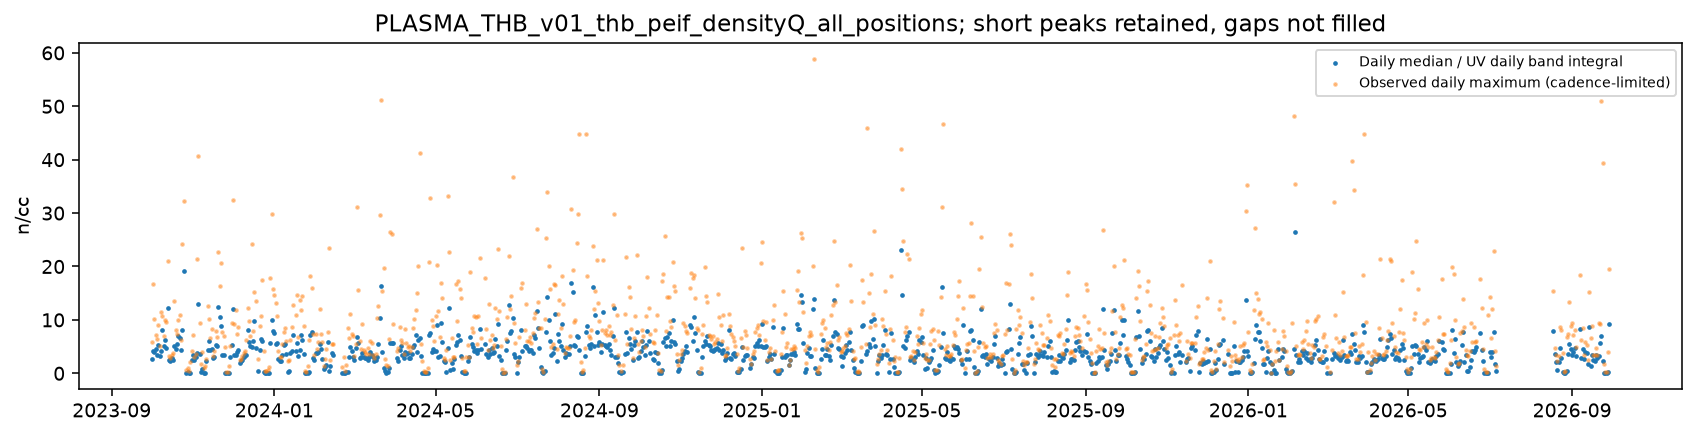

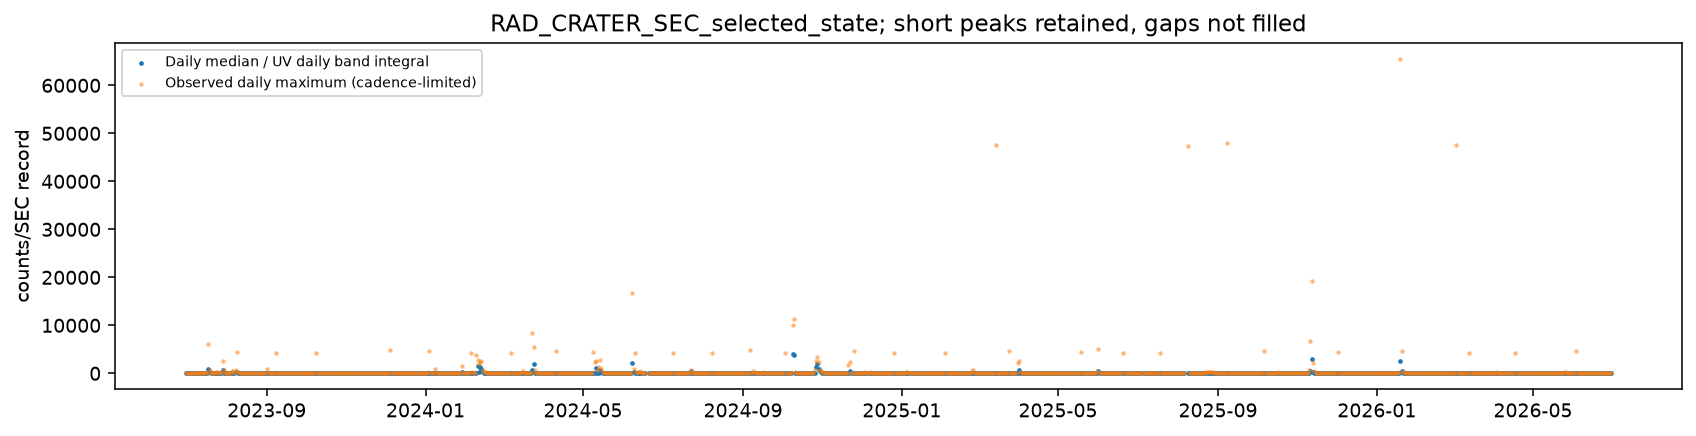

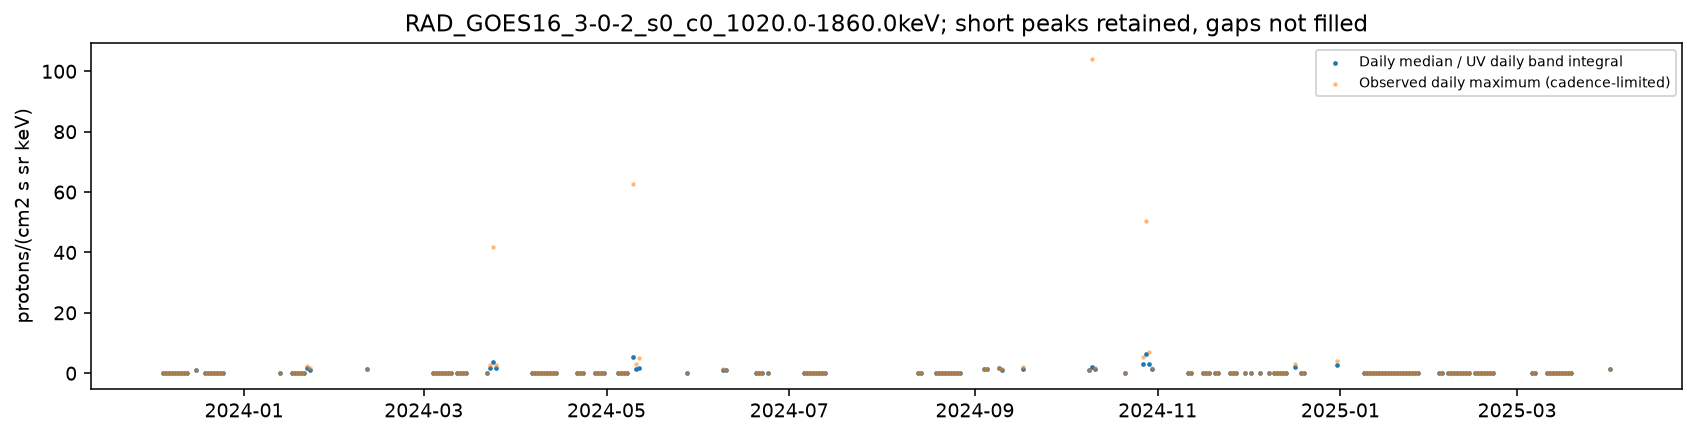

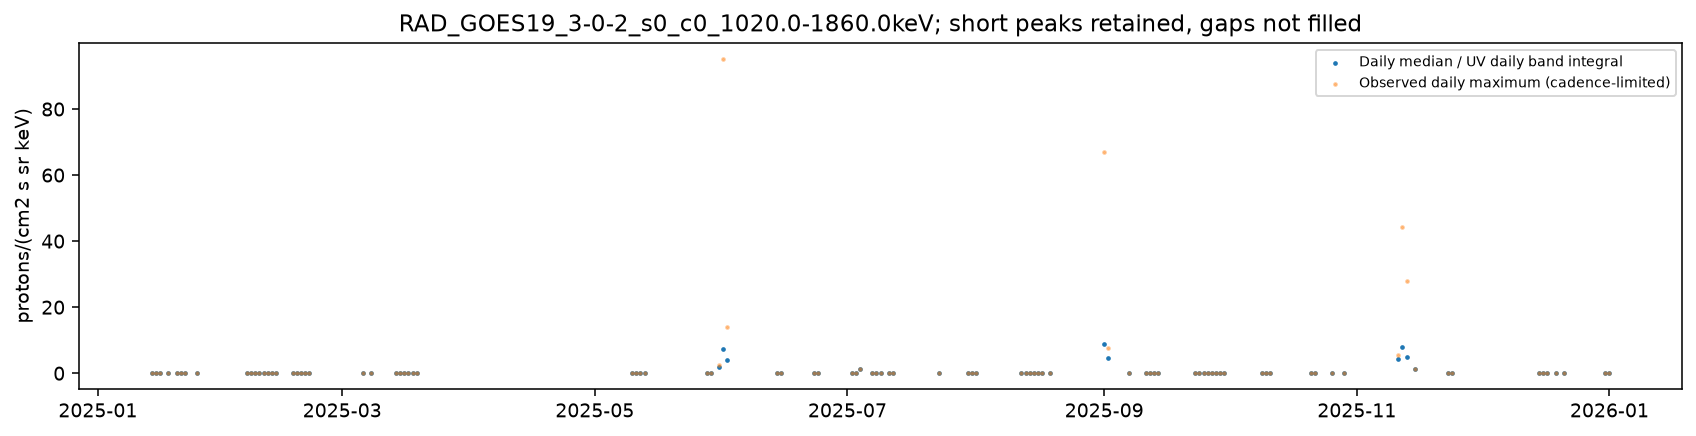

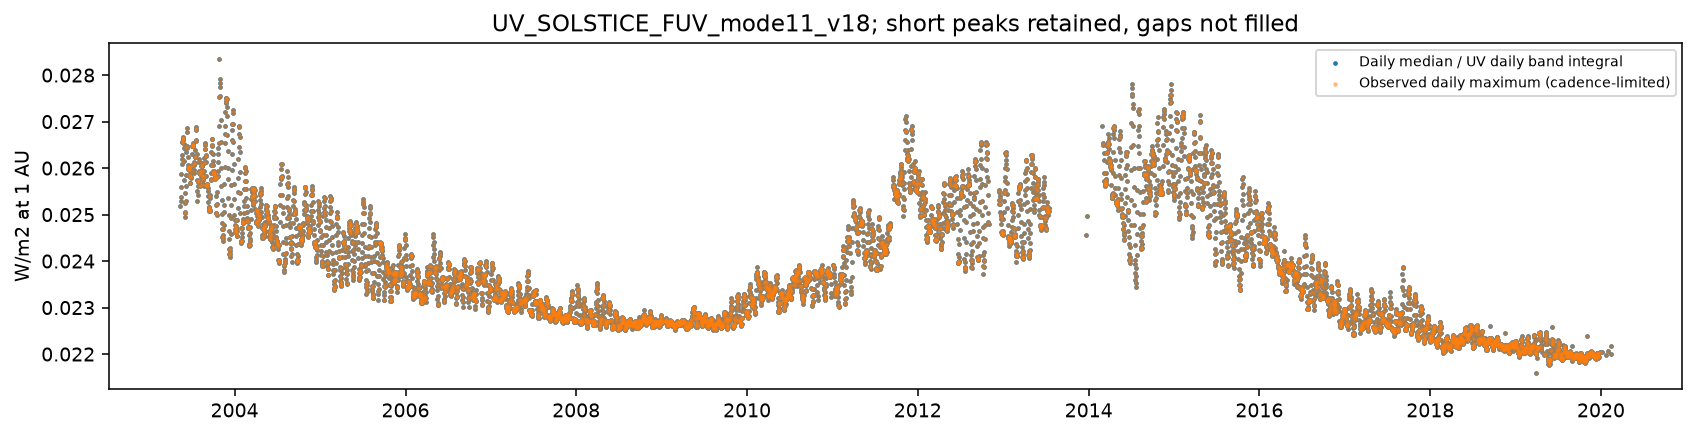

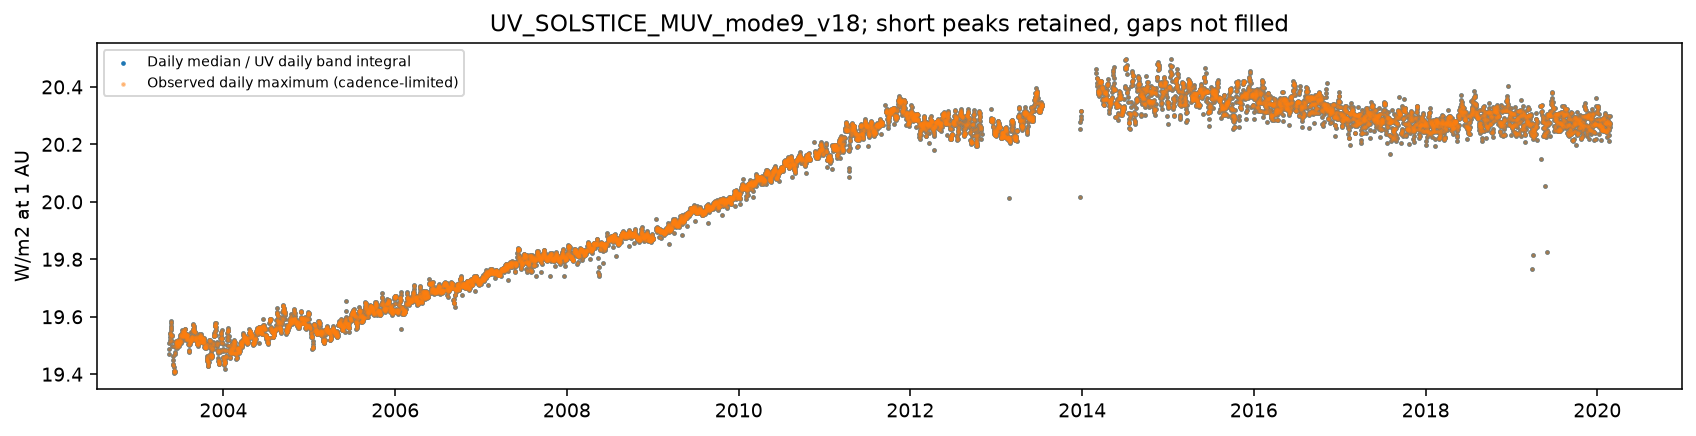

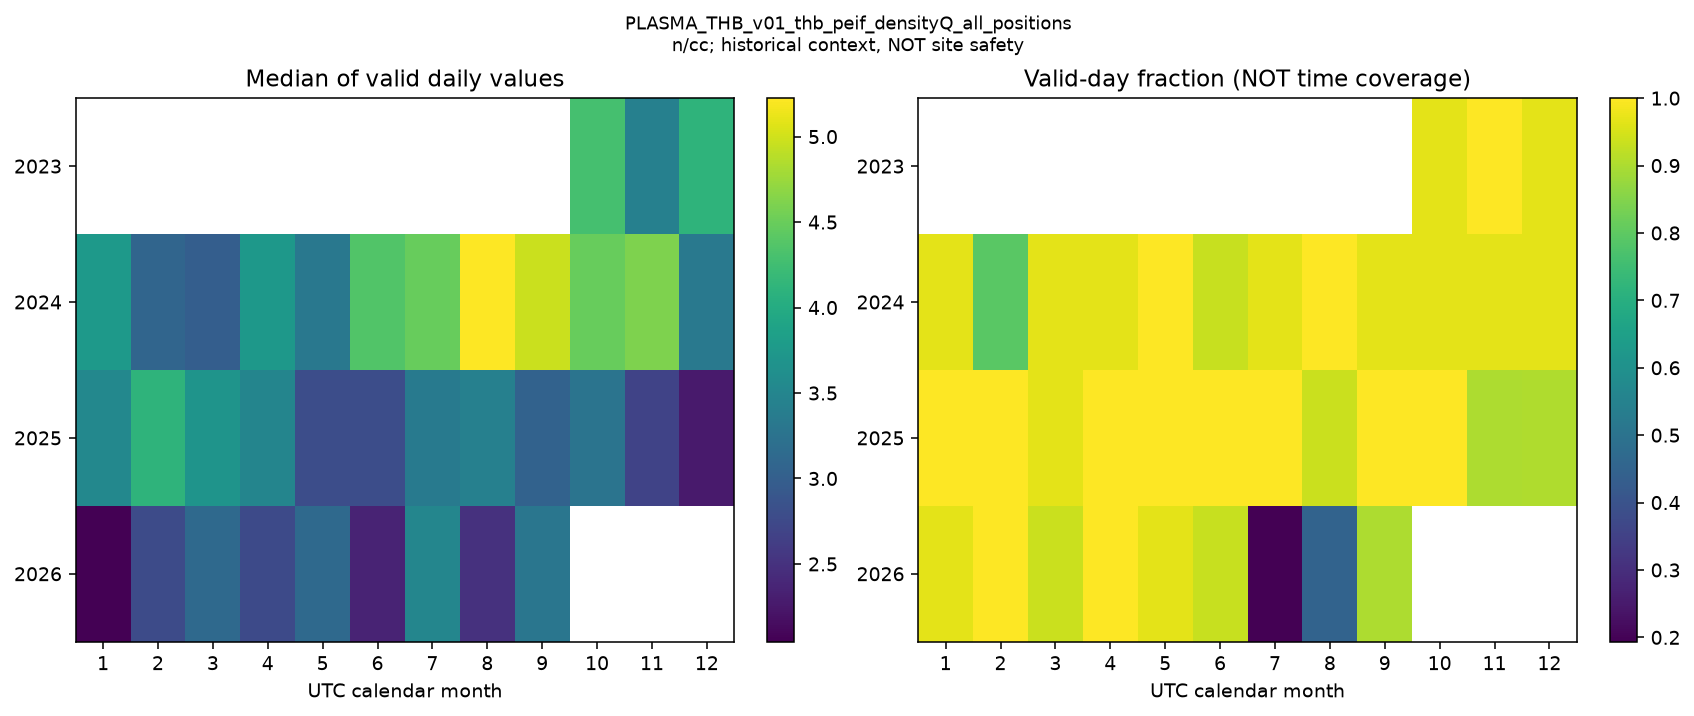

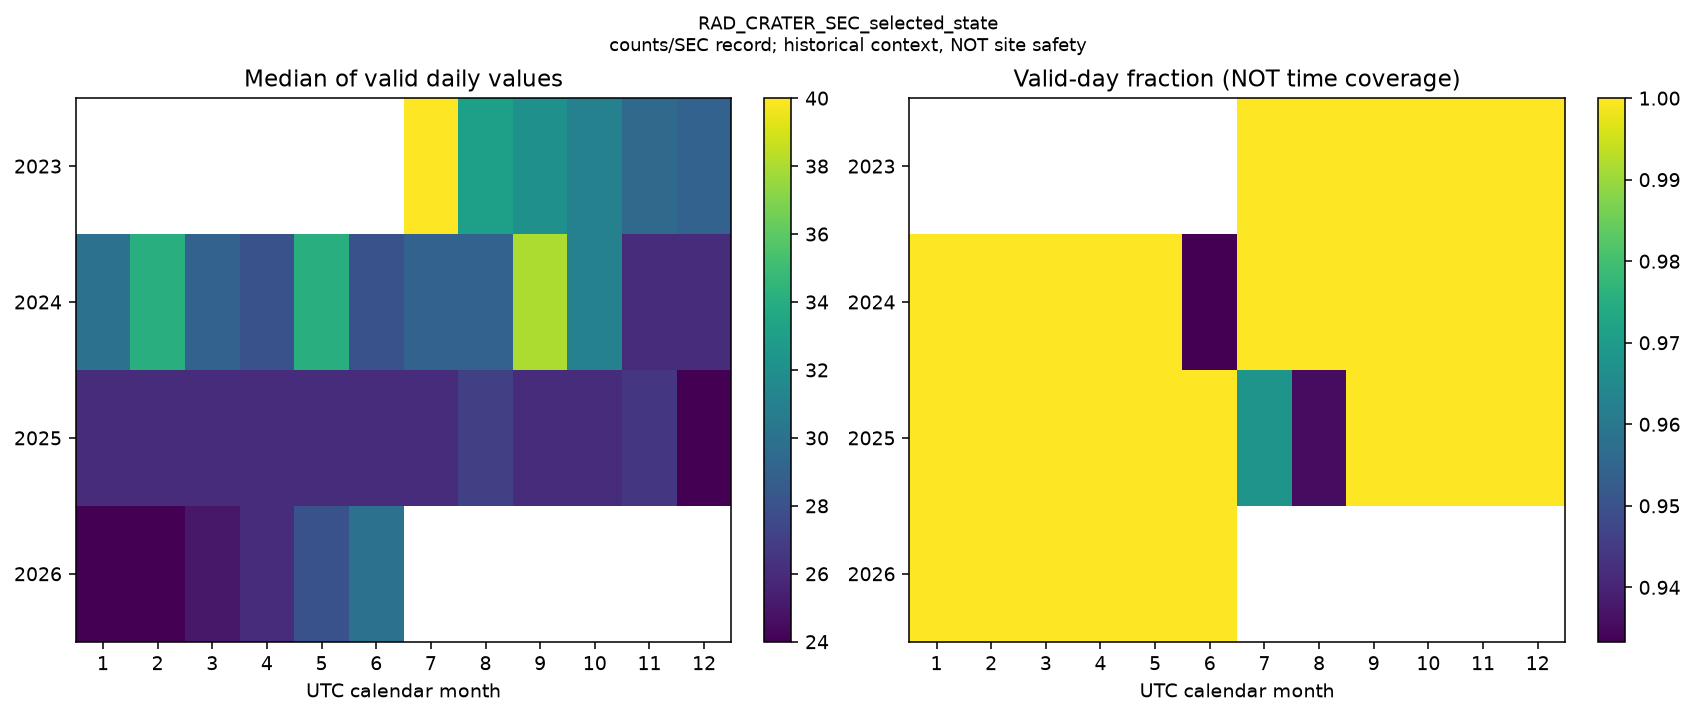

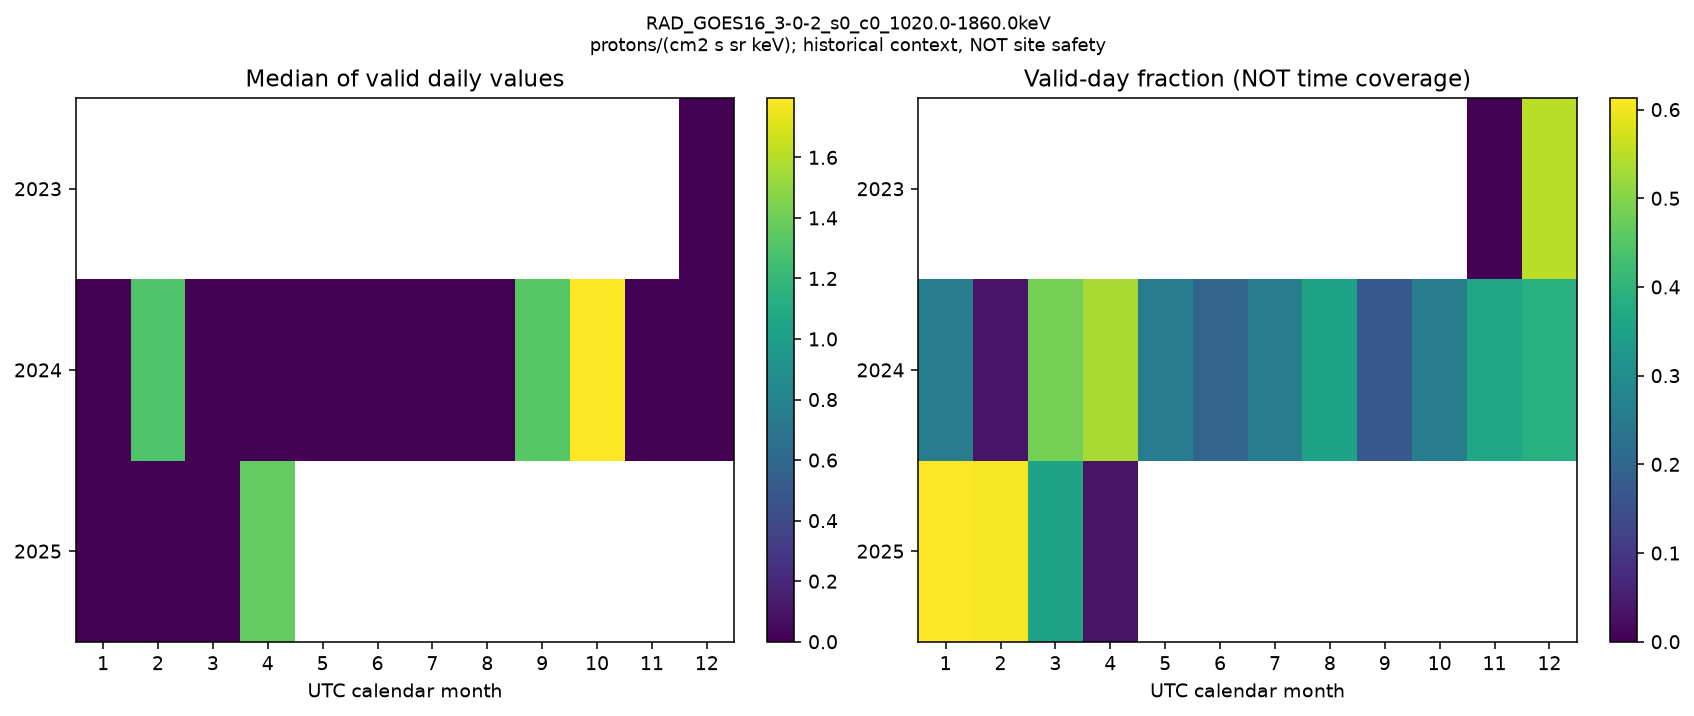

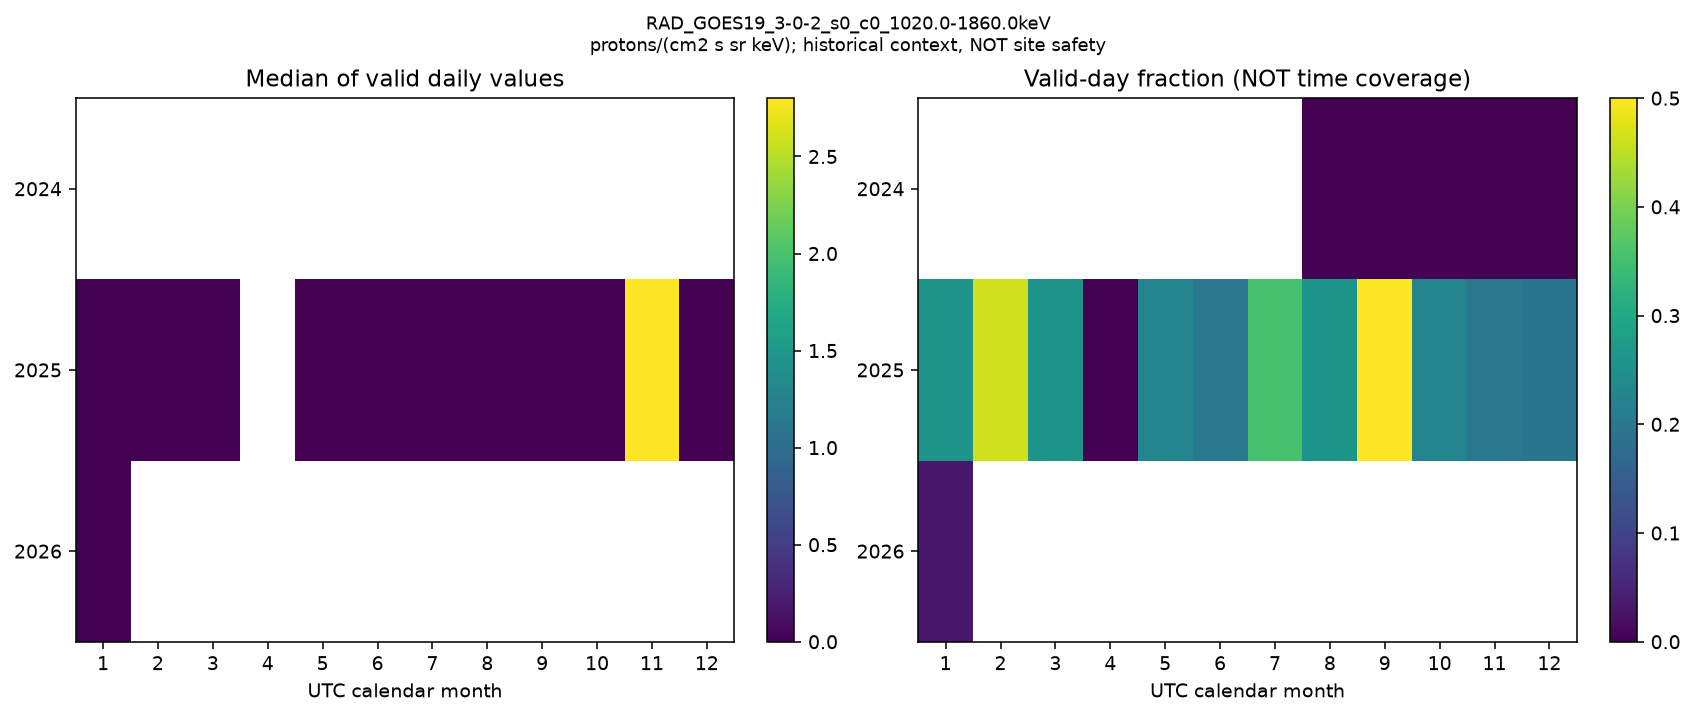

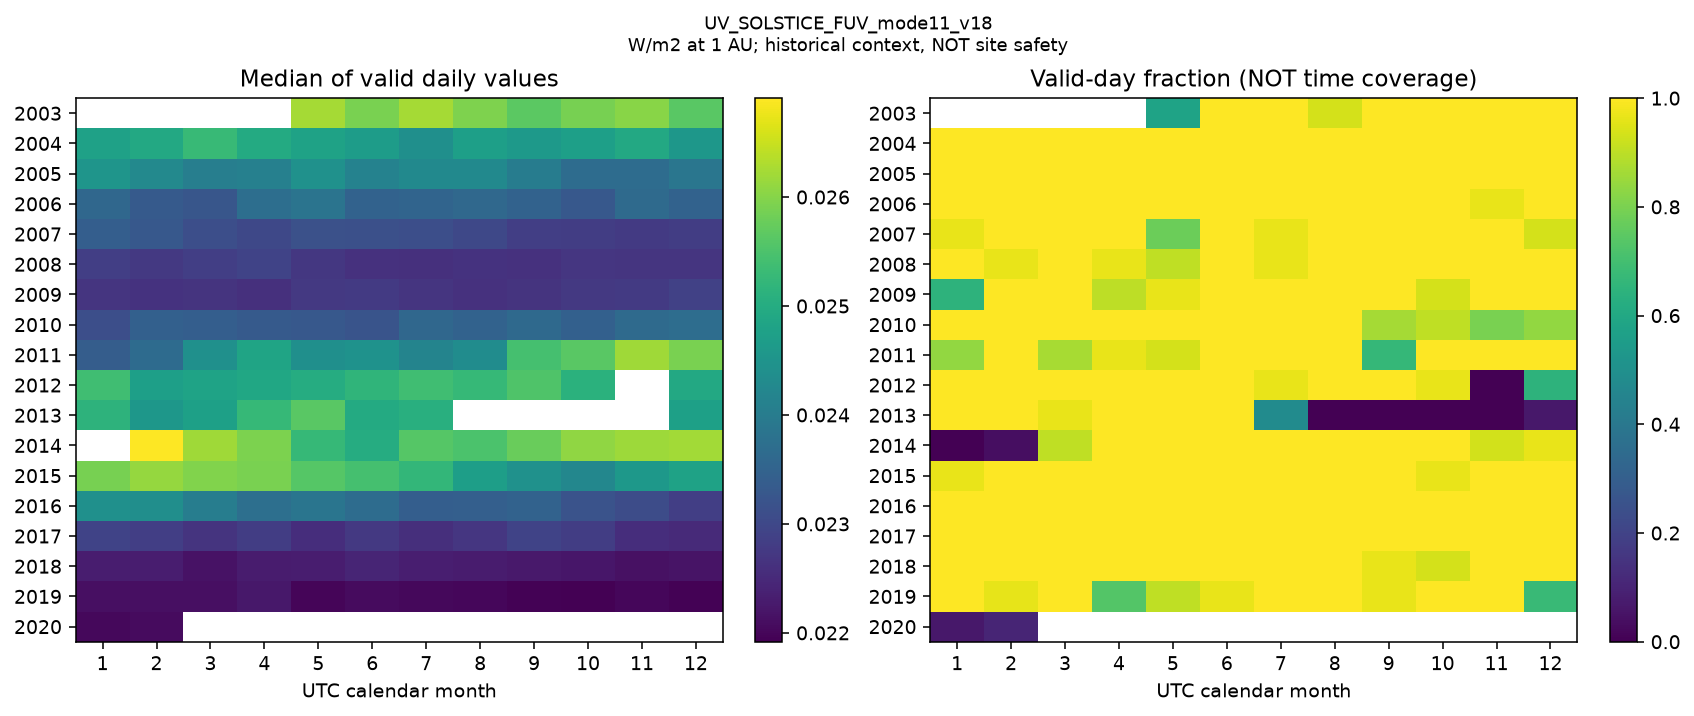

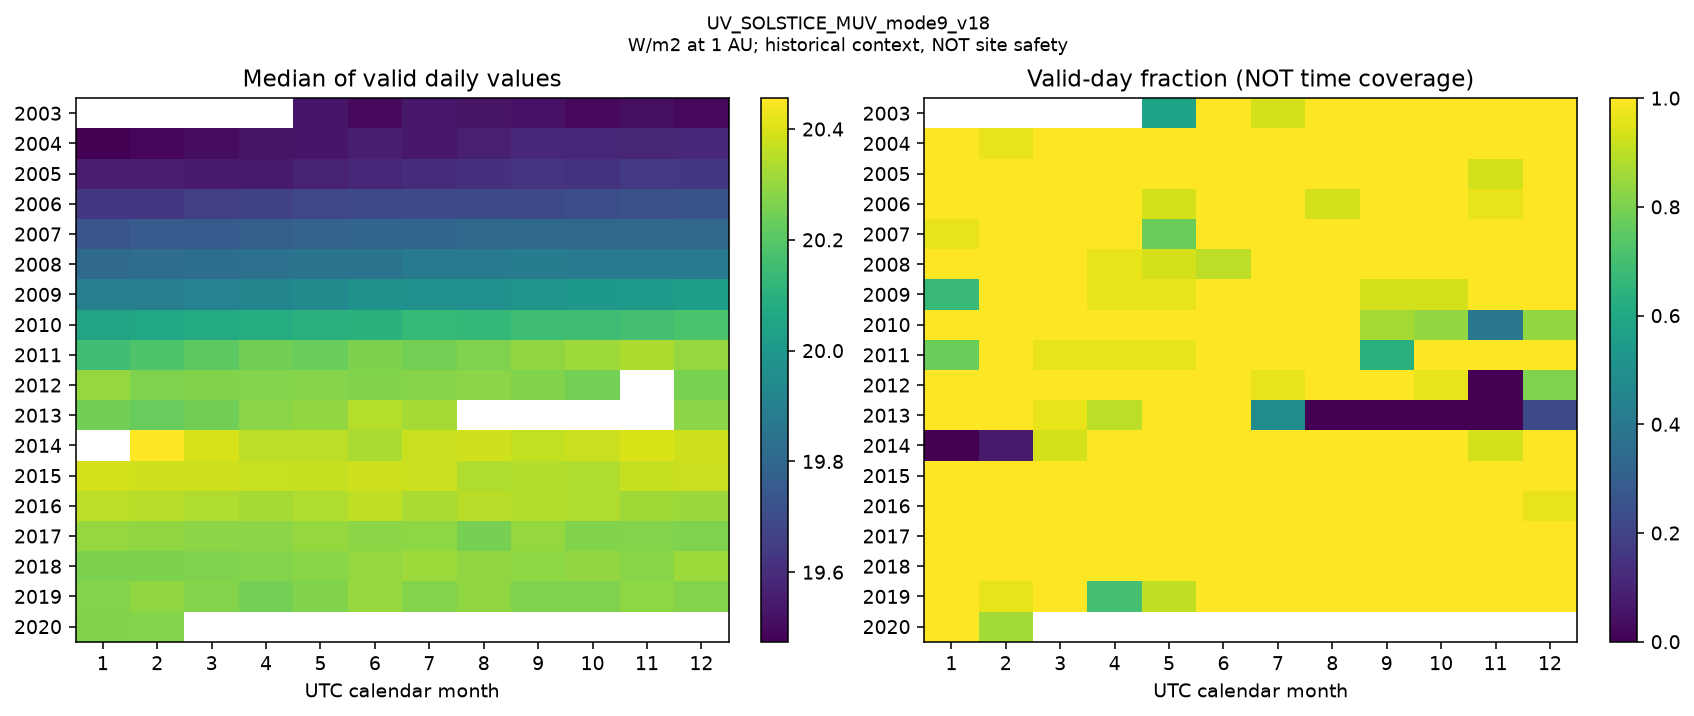

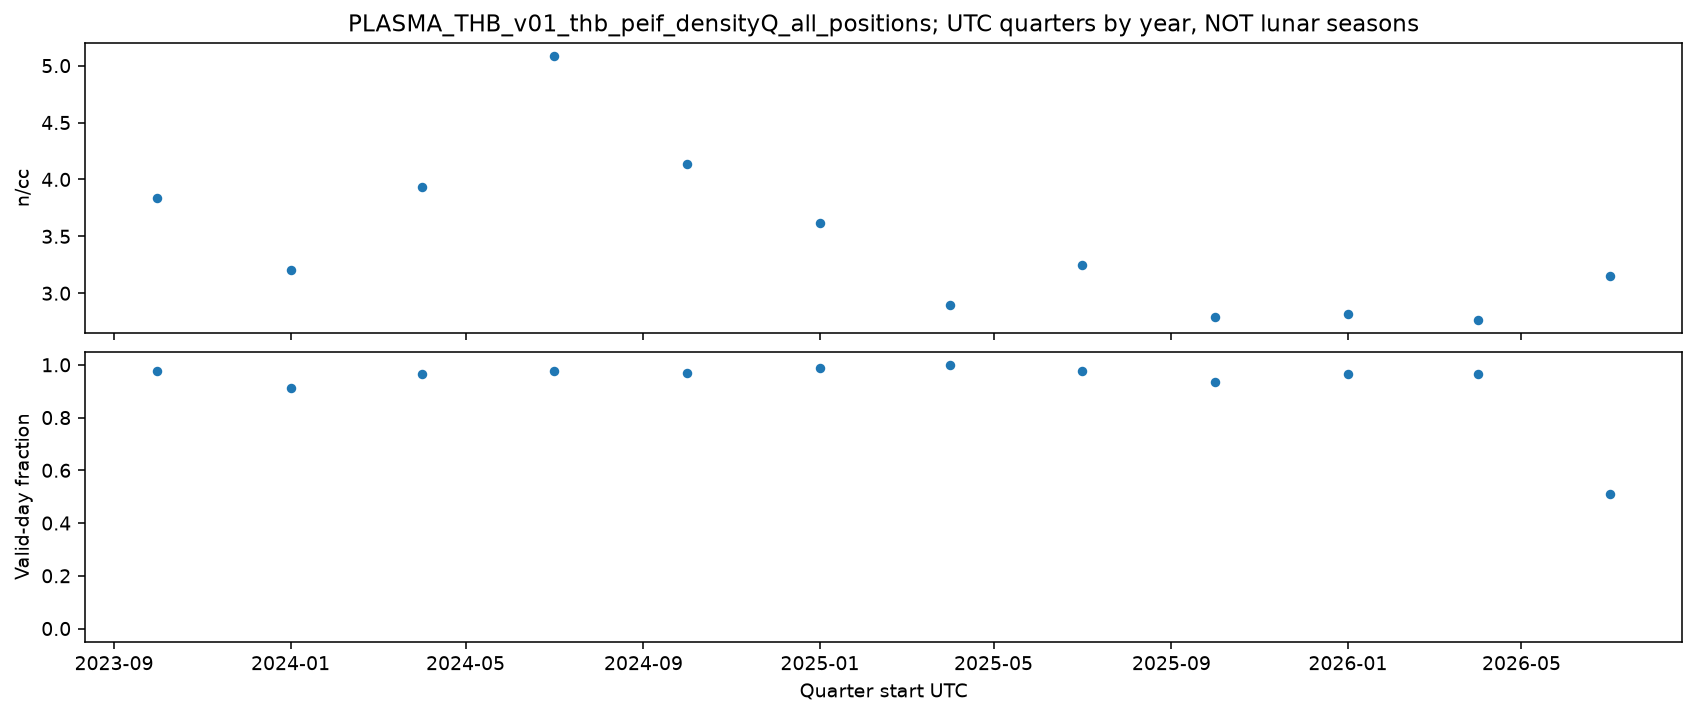

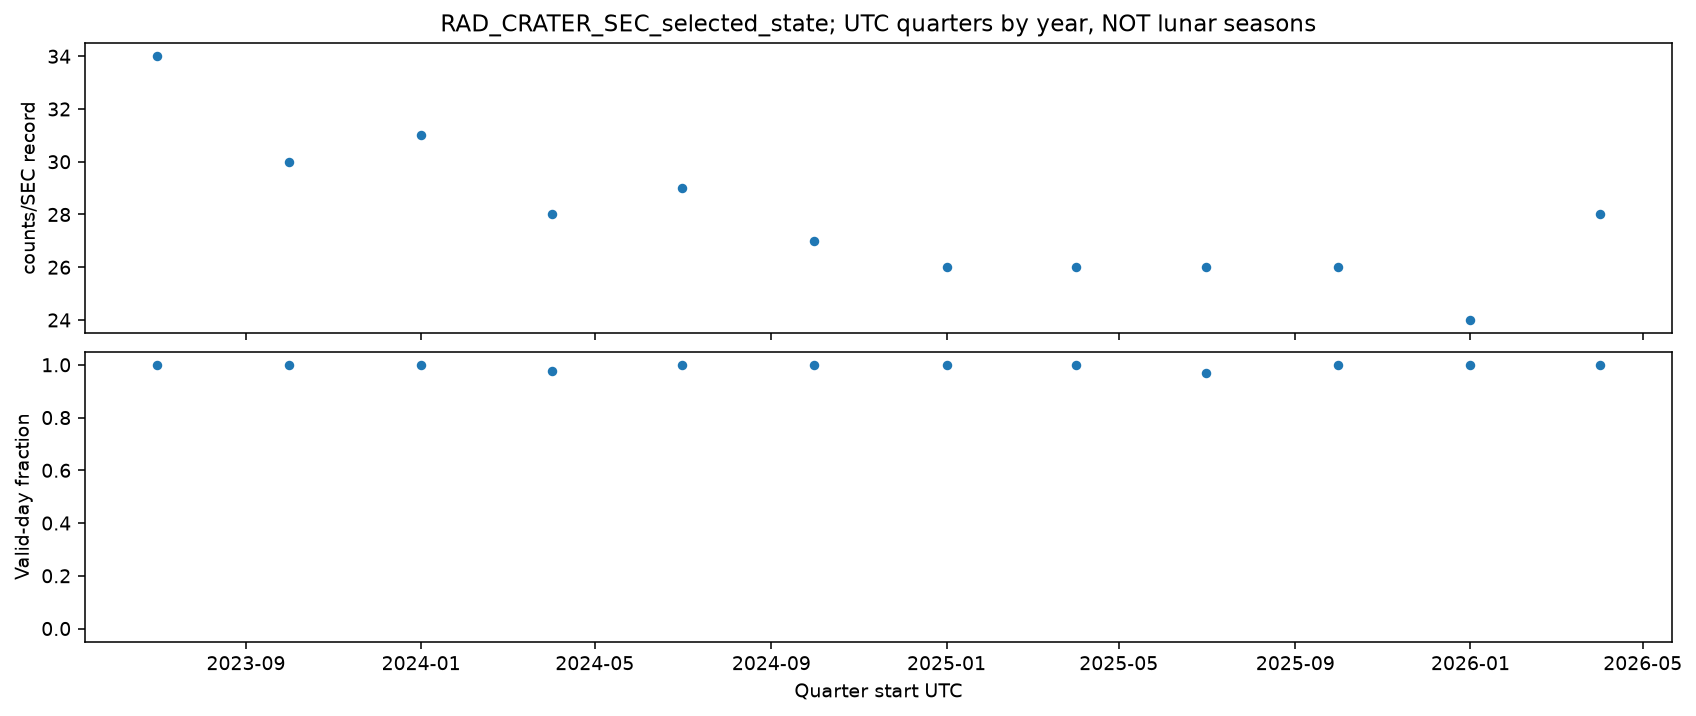

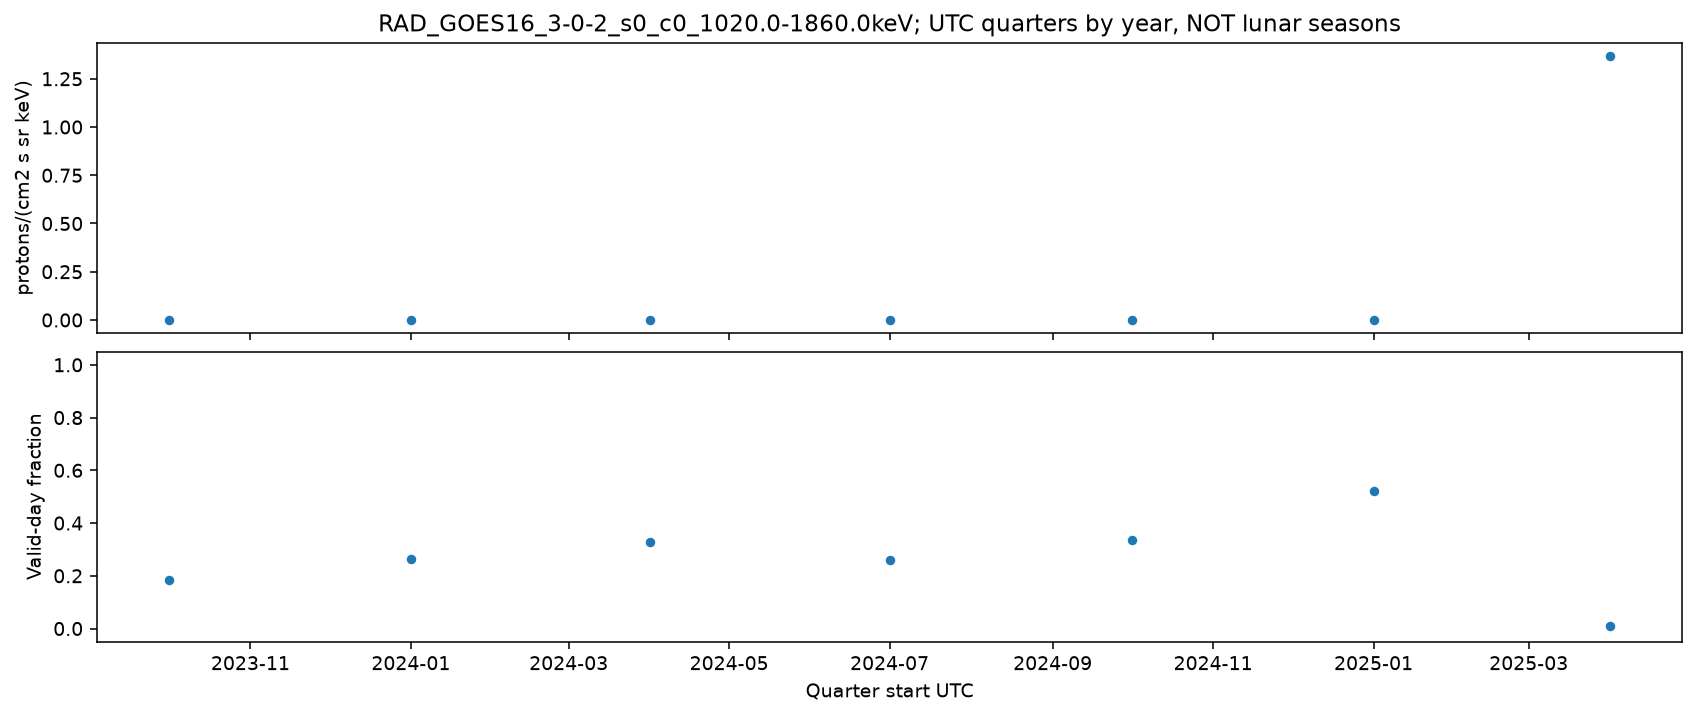

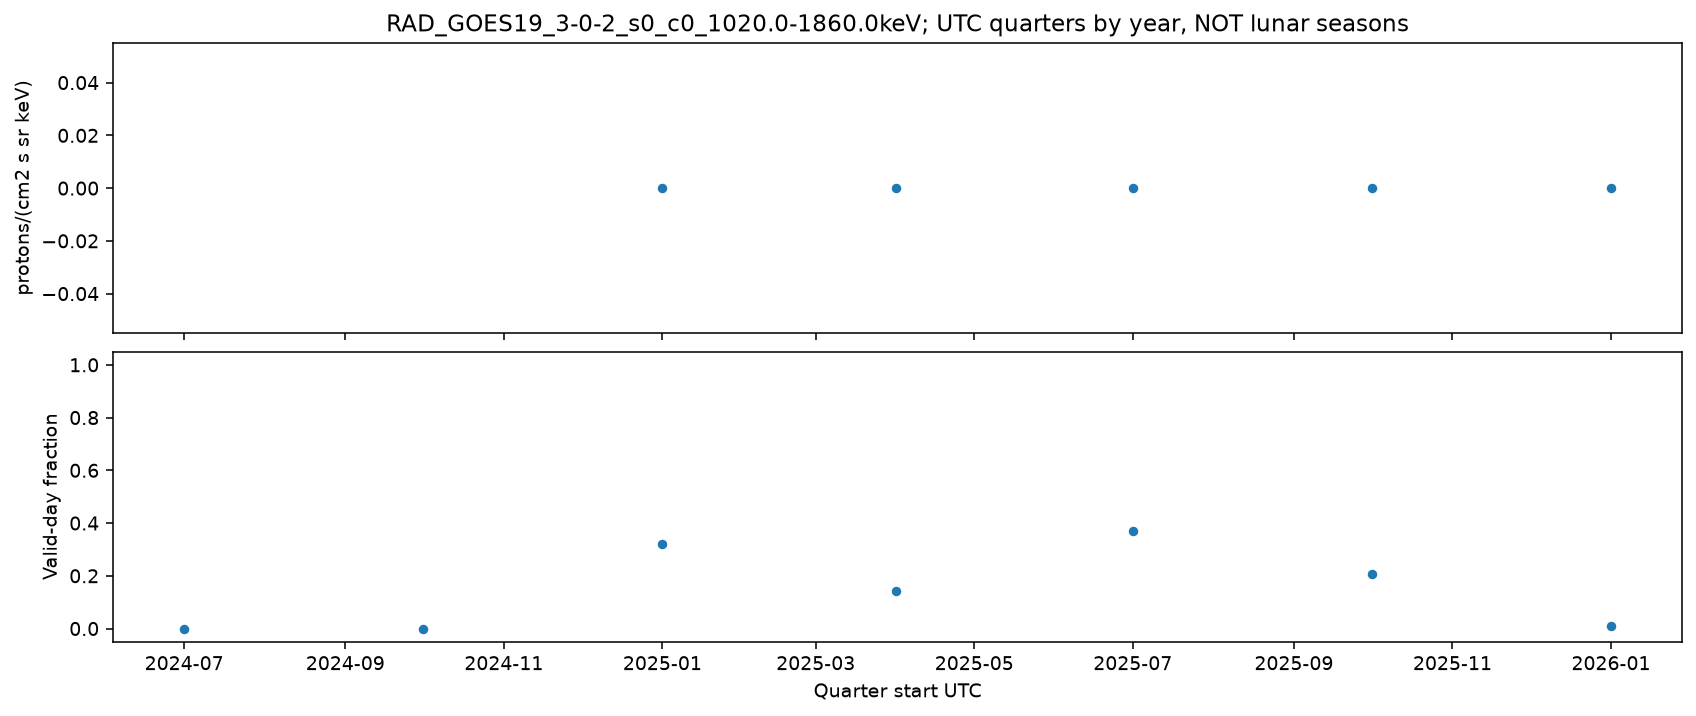

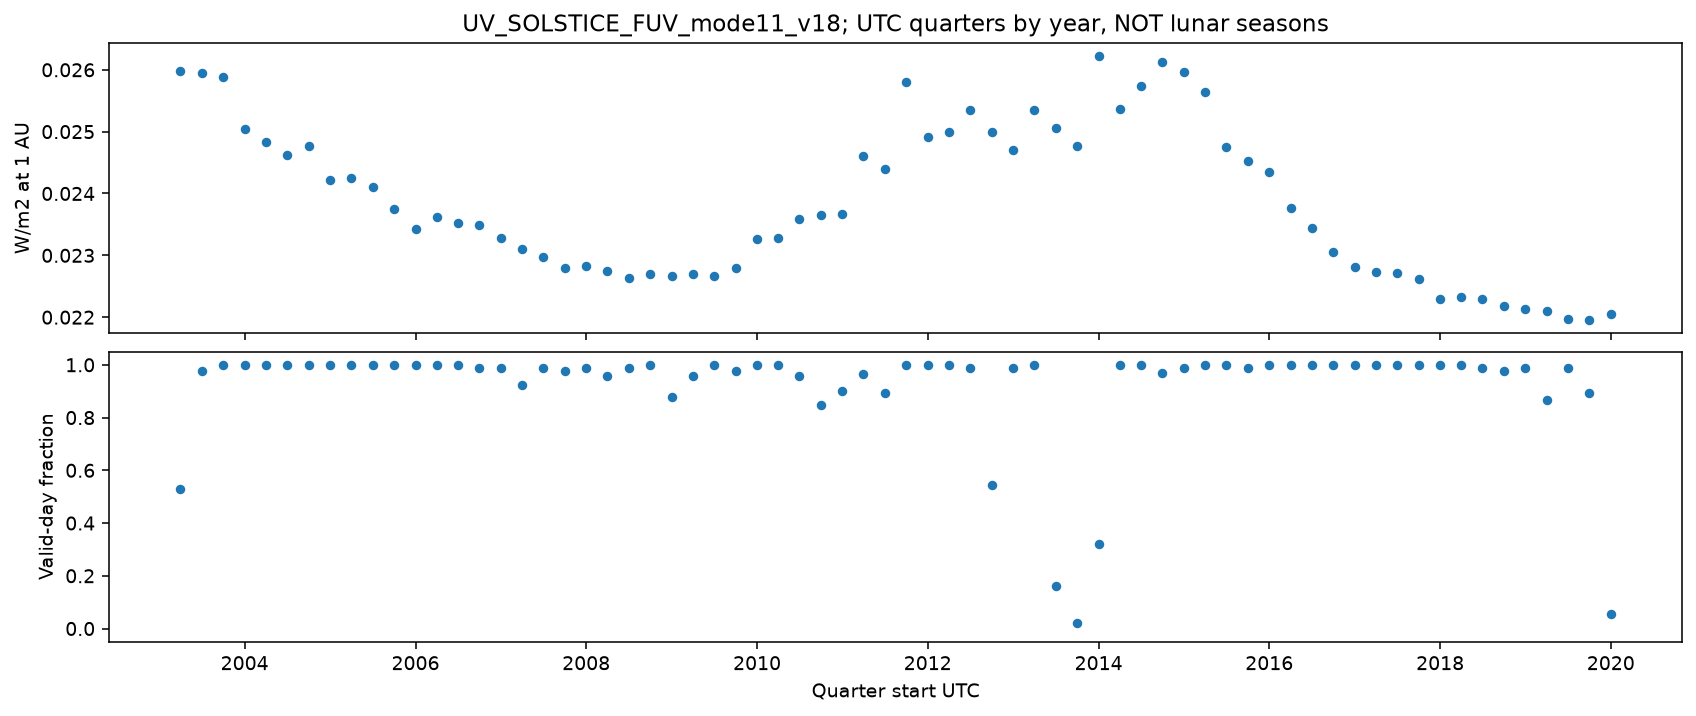

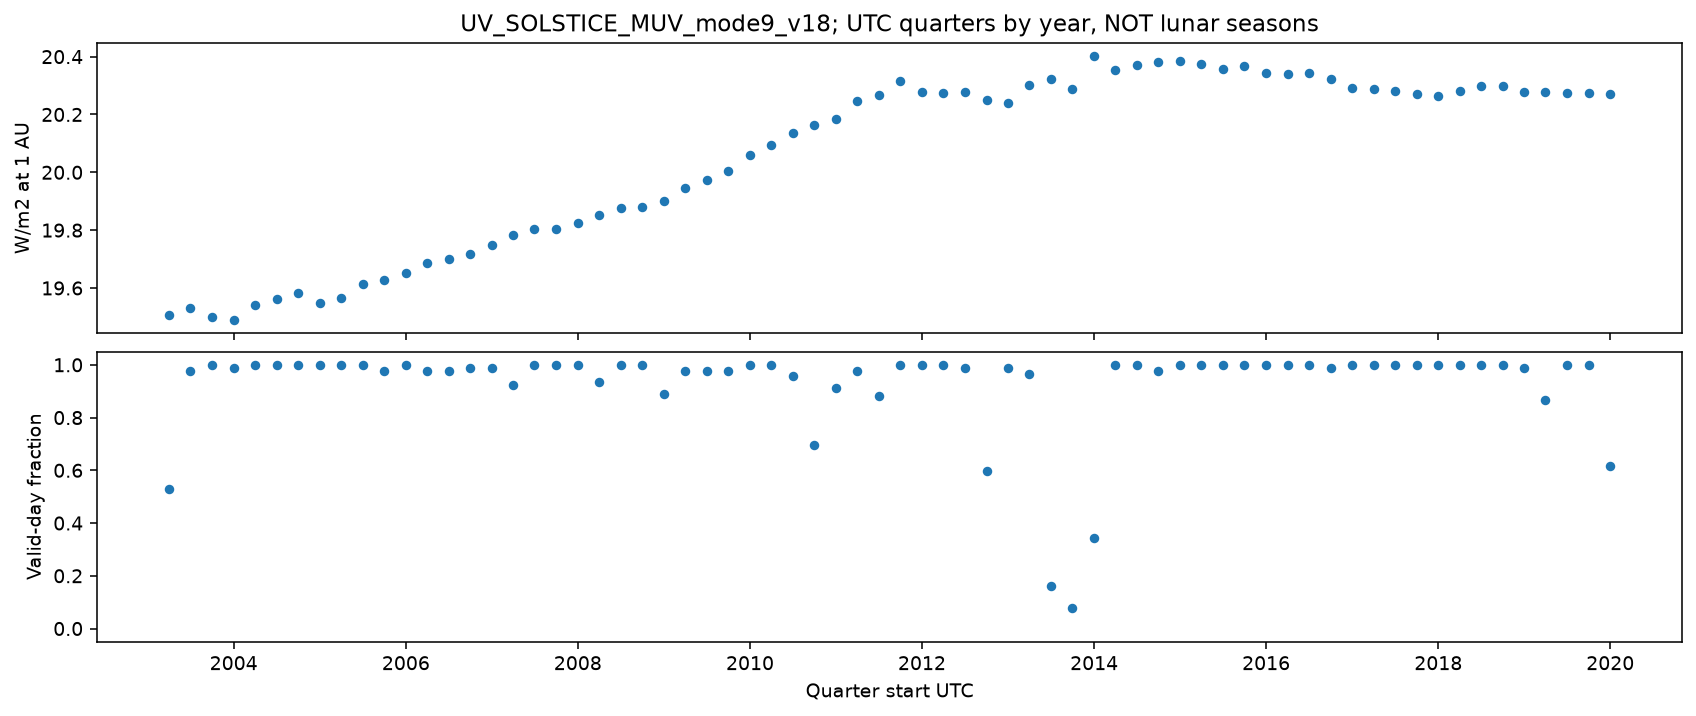

In [3]:
from IPython.display import Image, display
for path in sorted(folder.glob("*.png")):
    display(Image(filename=str(path)))

## Decision boundary

These results supply Step 4 evidence-use guards and Step 5 historical context, not new safety limits or ranking weights. Lower density, darker conditions or a quieter historical month is not automatically safer. Candidate operational conclusions remain **Unknown** without applicable mission-window/environment/response evidence. See [EDA Notes](../../EDA_Notes.md) and [pipeline](../../../Pipeline_Proto/README.md).